In [1]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False


import pandas as pd
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor 
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression,SGDClassifier
from sklearn.preprocessing import PolynomialFeatures,StandardScaler,OneHotEncoder
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax # expit:이진분류함수, softmax:다중분류 함수 0-1숫자로 변환
import numpy as np
from io import StringIO

In [2]:
# 데이터 불러오기
fish = pd.read_csv('data/fish_logistic.csv')
fish.head(2)

,Species,Weight,Length,Diagonal,Height,Width
0,Bream,242.0,25.4,30.0,11.52,4.0200
1,Bream,290.0,26.3,31.2,12.48,4.3056


In [3]:
# 데이터 분리
data = fish[fish.columns[1:]].values
label = fish['Species'].values

train_data,test_data,train_label,test_label = train_test_split(data,label,random_state=42)
data

array([[2.42000e+02, 2.54000e+01, 3.00000e+01, 1.15200e+01, 4.02000e+00],
       [2.90000e+02, 2.63000e+01, 3.12000e+01, 1.24800e+01, 4.30560e+00],
       [3.40000e+02, 2.65000e+01, 3.11000e+01, 1.23778e+01, 4.69610e+00],
       [3.63000e+02, 2.90000e+01, 3.35000e+01, 1.27300e+01, 4.45550e+00],
       [4.30000e+02, 2.90000e+01, 3.40000e+01, 1.24440e+01, 5.13400e+00],
       [4.50000e+02, 2.97000e+01, 3.47000e+01, 1.36024e+01, 4.92740e+00],
       [5.00000e+02, 2.97000e+01, 3.45000e+01, 1.41795e+01, 5.27850e+00],
       [3.90000e+02, 3.00000e+01, 3.50000e+01, 1.26700e+01, 4.69000e+00],
       [4.50000e+02, 3.00000e+01, 3.51000e+01, 1.40049e+01, 4.84380e+00],
       [5.00000e+02, 3.07000e+01, 3.62000e+01, 1.42266e+01, 4.95940e+00],
       [4.75000e+02, 3.10000e+01, 3.62000e+01, 1.42628e+01, 5.10420e+00],
       [5.00000e+02, 3.10000e+01, 3.62000e+01, 1.43714e+01, 4.81460e+00],
       [5.00000e+02, 3.15000e+01, 3.64000e+01, 1.37592e+01, 4.36800e+00],
       [3.40000e+02, 3.20000e+01, 3.73

In [4]:
# 정규화
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [7]:
# 데이터 학습
# lr = LogisticRegression(C=20,max_iter=1000) 이 함수보다 큰 원 느낌인 함수 sc안에 lr이 포함되어있음
# loss='log_loss' : LogisticRegression log 함수
# max_iter =10 : 10번 반복
# randem_state=42: 랜던선택을 고정 - 연습할때만 사용
# verbose = 1 : 반벅하면서 정보를 보여줌, / 설정하지 않으면 보여주지 않음
sc = SGDClassifier(loss='log_loss',random_state=42)
train_score = []  # train 정확도값 추가
test_score = [] # test 정확도값 추가


# 정답지 필요
# classes = np.unique(train_label)
classes = train_label.unique()

for i in range(300):
    sc.partial_fit(train_scaled,train_label,classes=classes)
    train_score.append(sc.score(train_scaled,train_label))
    test_score.append(sc.score(test_scaled,test_label))


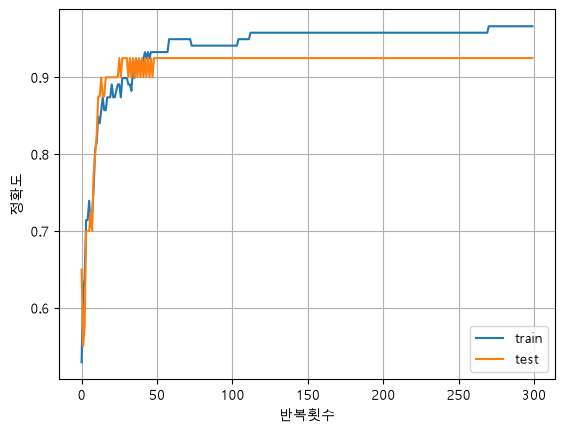

In [13]:
plt.Figure(figsize=(10,6))
plt.plot(train_score)
plt.plot(test_score)
plt.xlabel('반복횟수')
plt.ylabel('정확도')
plt.grid()
plt.legend(('train','test'))
plt.show()

In [28]:
# tol = max_iter 반복할때 일정 기간동안 변동이 없으면 자동으로 중지하는데. 그 자동중지를 해제함
sc =SGDClassifier(loss='log_loss',max_iter=50,tol=None,random_state=42)
sc.fit(train_scaled,train_label)
print('trian_정확도',sc.score(train_scaled,train_label))
print('test_정확도',sc.score(test_scaled,test_label))

trian_정확도 0.9243697478991597
test_정확도 0.925
